# Operasi Area: Filter Konvolusi pada Foto

**Jenis operasi:** operasi area (lokal/ketetanggaan) pada domain spasial.
**Metode:** konvolusi spasial 2D dengan kernel.

$$g(x,y)=\sum_{i}\sum_{j} w(i,j)\,f(x-i,\,y-j)$$

**Filter yang diimplementasikan:** Mean, Gaussian, Sharpening, Sobel, Laplacian.

Penjelasan teori ada di `penjelasan_filter_konvolusi.pdf`.

In [1]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

## 1. Input foto
Foto dibaca, diperkecil (agar proses cepat), lalu diubah ke **grayscale** karena filter diterapkan pada satu kanal intensitas.

Untuk memakai foto lain (Google Colab), hapus tanda `#` pada tiga baris upload.

Ukuran citra (tinggi, lebar): (640, 480)


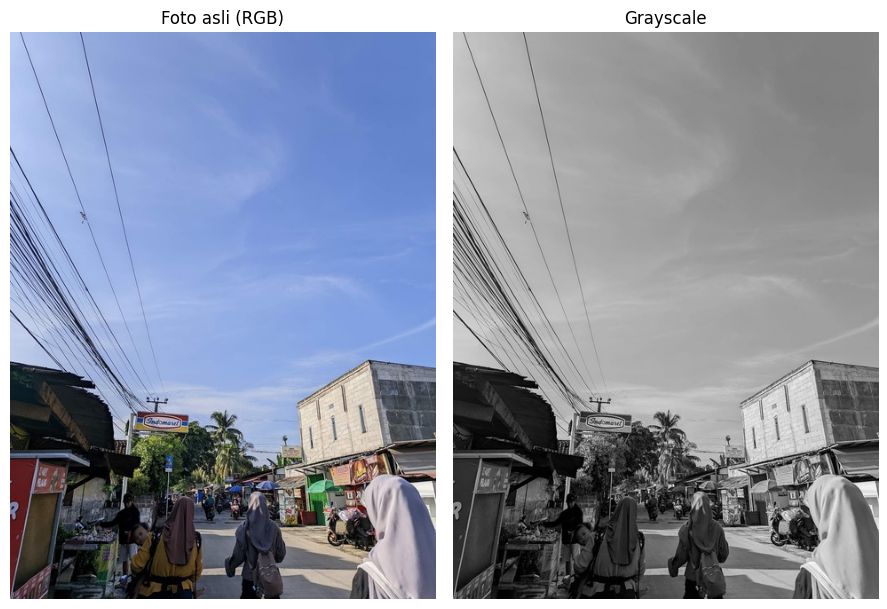

In [2]:
PATH_FOTO = "foto_uji.jpg"
LEBAR_MAKS = 480          # foto diperkecil agar konvolusi cepat

# --- Khusus Google Colab: hapus tanda # untuk upload foto sendiri ---
# from google.colab import files
# up = files.upload()
# PATH_FOTO = list(up.keys())[0]

foto = Image.open(PATH_FOTO).convert("RGB")
if foto.width > LEBAR_MAKS:
    foto = foto.resize((LEBAR_MAKS, round(foto.height * LEBAR_MAKS / foto.width)), Image.LANCZOS)

citra = np.array(foto.convert("L"), dtype=np.uint8)    # grayscale 0-255
print("Ukuran citra (tinggi, lebar):", citra.shape)

fig, ax = plt.subplots(1, 2, figsize=(9, 6))
ax[0].imshow(foto); ax[0].set_title("Foto asli (RGB)"); ax[0].axis("off")
ax[1].imshow(citra, cmap="gray", vmin=0, vmax=255); ax[1].set_title("Grayscale"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 2. Konvolusi 2D (manual)
Langkah: **padding** → balik kernel → geser kernel (kalikan dan jumlahkan) → **clipping** atau normalisasi.

Perulangan dilakukan pada elemen kernel, bukan pada tiap piksel, sehingga jauh lebih cepat.

In [3]:
def konvolusi2d(citra, kernel, padding="reflect"):
    citra = citra.astype(np.float64)
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    H, W = citra.shape
    pad = np.pad(citra, ((ph, ph), (pw, pw)), mode=padding)   # 1. padding
    k = np.flipud(np.fliplr(kernel))                           # 2. balik kernel
    hasil = np.zeros((H, W))
    for i in range(kh):                                        # 3. kalikan & jumlahkan
        for j in range(kw):
            hasil += k[i, j] * pad[i:i + H, j:j + W]
    return hasil

def clip8(x):
    return np.clip(x, 0, 255).astype(np.uint8)                 # 4. batasi 0-255

def normalisasi(x):
    # untuk hasil deteksi tepi: nilai mutlak, diskala ke 0-255
    # (persentil 99,5 dipakai agar beberapa tepi sangat kuat tidak membuat sisanya gelap)
    x = np.abs(x)
    return clip8(255 * np.minimum(x / np.percentile(x, 99.5), 1))

### Contoh hitungan manual satu piksel (mean filter 3×3)

In [4]:
y, x = 300, 200
area = citra[y-1:y+2, x-1:x+2].astype(float)
k_demo = np.ones((3, 3)) / 9

print("Area 3x3 di sekitar piksel (baris 300, kolom 200):\n", area.astype(int))
print("\nHasil hitung manual :", round((area * k_demo).sum(), 2))
print("Hasil fungsi        :", round(konvolusi2d(citra, k_demo)[y, x], 2))

Area 3x3 di sekitar piksel (baris 300, kolom 200):
 [[182 182 181]
 [182 183 183]
 [182 182 182]]

Hasil hitung manual : 182.11
Hasil fungsi        : 182.11


## 3. Definisi kernel

In [5]:
def kernel_gaussian(ukuran=5, sigma=1.0):
    a = np.arange(ukuran) - ukuran // 2
    xx, yy = np.meshgrid(a, a)
    k = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    return k / k.sum()                       # dinormalisasi: jumlah = 1

kernel_mean      = np.ones((5, 5)) / 25
kernel_gauss     = kernel_gaussian(5, 1.0)
kernel_laplacian = np.array([[0,  1, 0],
                             [1, -4, 1],
                             [0,  1, 0]])
kernel_sharpen   = np.array([[0, 0, 0],
                             [0, 1, 0],
                             [0, 0, 0]]) - kernel_laplacian    # identitas - Laplacian
kernel_sobel_x   = np.array([[-1, 0, 1],
                             [-2, 0, 2],
                             [-1, 0, 1]])
kernel_sobel_y   = np.array([[-1, -2, -1],
                             [ 0,  0,  0],
                             [ 1,  2,  1]])

print("Kernel sharpening (identitas - Laplacian):\n", kernel_sharpen)
print("\nJumlah elemen kernel:")
print("  Mean      :", kernel_mean.sum().round(3))
print("  Gaussian  :", kernel_gauss.sum().round(3))
print("  Sharpen   :", kernel_sharpen.sum())
print("  Sobel X   :", kernel_sobel_x.sum(), " (0 -> area rata menghasilkan 0)")
print("  Laplacian :", kernel_laplacian.sum(), " (0 -> area rata menghasilkan 0)")

Kernel sharpening (identitas - Laplacian):
 [[ 0 -1  0]
 [-1  5 -1]
 [ 0 -1  0]]

Jumlah elemen kernel:
  Mean      : 1.0
  Gaussian  : 1.0
  Sharpen   : 1
  Sobel X   : 0  (0 -> area rata menghasilkan 0)
  Laplacian : 0  (0 -> area rata menghasilkan 0)


## 4. Terapkan semua filter

In [6]:
hasil_mean    = clip8(konvolusi2d(citra, kernel_mean))
hasil_gauss   = clip8(konvolusi2d(citra, kernel_gauss))
hasil_sharpen = clip8(konvolusi2d(citra, kernel_sharpen))

gx = konvolusi2d(citra, kernel_sobel_x)
gy = konvolusi2d(citra, kernel_sobel_y)
hasil_sobel = normalisasi(np.sqrt(gx**2 + gy**2))      # magnitudo gradien

hasil_laplacian = normalisasi(konvolusi2d(citra, kernel_laplacian))

## 5. Visualisasi perbandingan

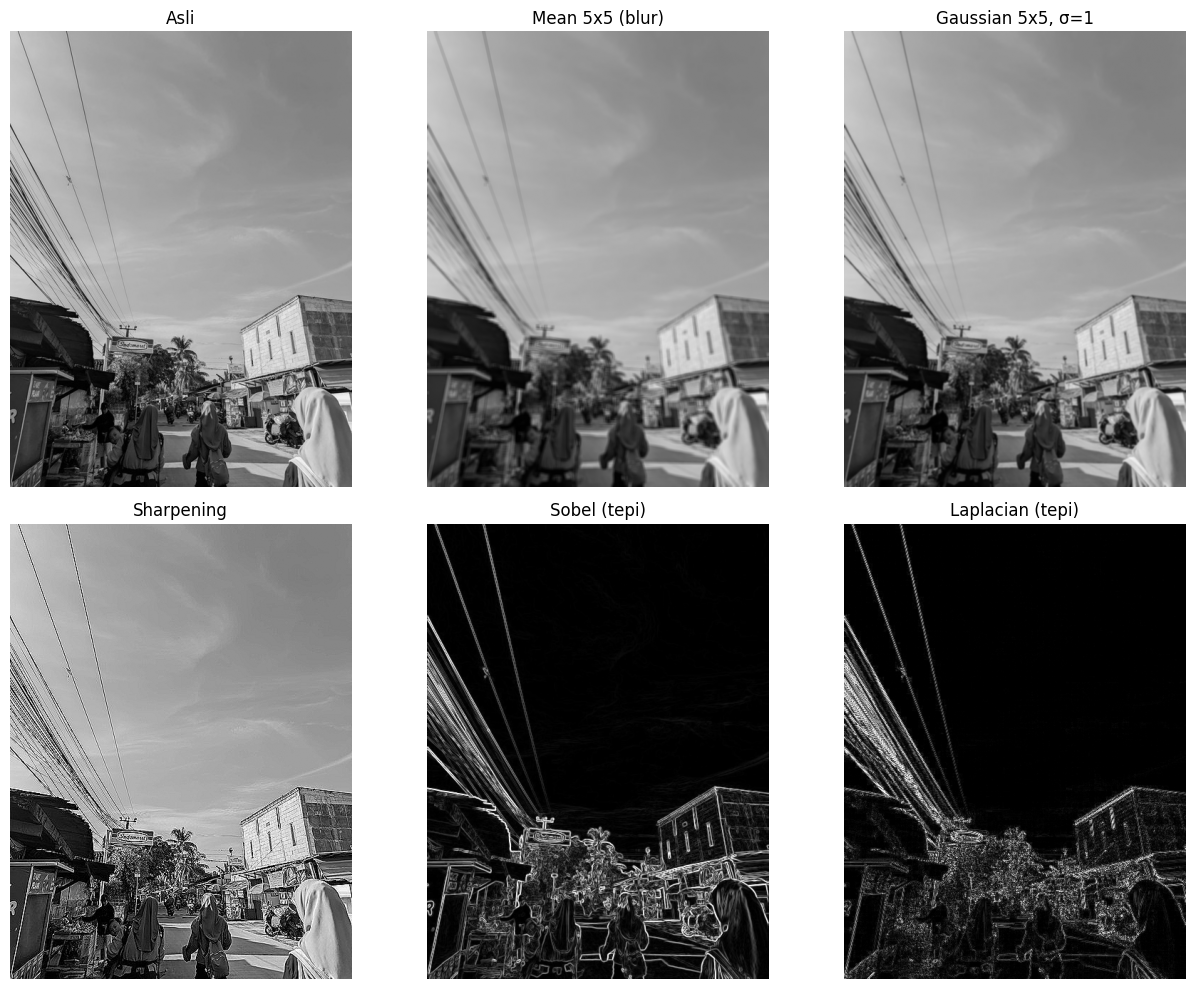

In [7]:
daftar = [("Asli", citra), ("Mean 5x5 (blur)", hasil_mean), ("Gaussian 5x5, σ=1", hasil_gauss),
          ("Sharpening", hasil_sharpen), ("Sobel (tepi)", hasil_sobel), ("Laplacian (tepi)", hasil_laplacian)]

fig, ax = plt.subplots(2, 3, figsize=(13, 10))
for a, (judul, img) in zip(ax.ravel(), daftar):
    a.imshow(img, cmap="gray", vmin=0, vmax=255); a.set_title(judul); a.axis("off")
plt.tight_layout()
plt.savefig("perbandingan_konvolusi.png", dpi=120)
plt.show()

### Komponen Sobel: Gx, Gy, dan magnitudo

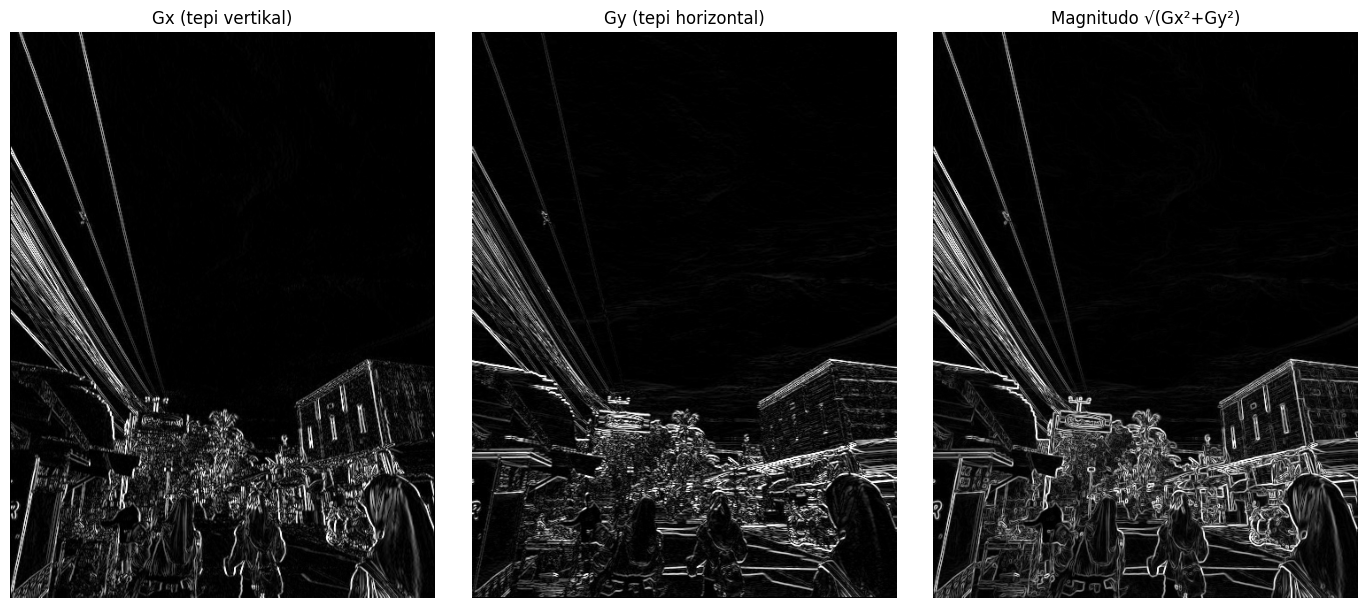

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 6))
ax[0].imshow(normalisasi(gx), cmap="gray"); ax[0].set_title("Gx (tepi vertikal)")
ax[1].imshow(normalisasi(gy), cmap="gray"); ax[1].set_title("Gy (tepi horizontal)")
ax[2].imshow(hasil_sobel, cmap="gray");     ax[2].set_title("Magnitudo √(Gx²+Gy²)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 6. Laplacian langsung vs Gaussian dulu
Laplacian sensitif terhadap noise dan tekstur halus (misalnya dedaunan). Cara mengatasinya: **blur Gaussian dulu, baru Laplacian** (*Laplacian of Gaussian*).

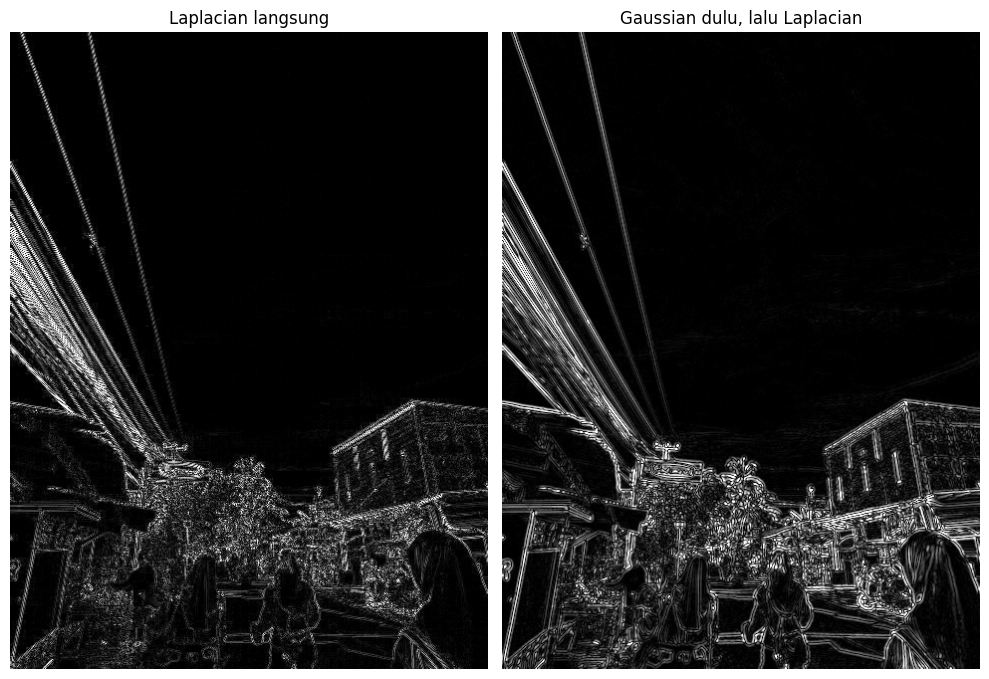

In [9]:
log = normalisasi(konvolusi2d(konvolusi2d(citra, kernel_gauss), kernel_laplacian))

fig, ax = plt.subplots(1, 2, figsize=(10, 7))
ax[0].imshow(hasil_laplacian, cmap="gray"); ax[0].set_title("Laplacian langsung")
ax[1].imshow(log, cmap="gray");             ax[1].set_title("Gaussian dulu, lalu Laplacian")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 7. Pengaruh ukuran kernel dan sigma
Kernel yang lebih besar atau sigma yang lebih besar membuat blur lebih kuat, tetapi detail ikut hilang.

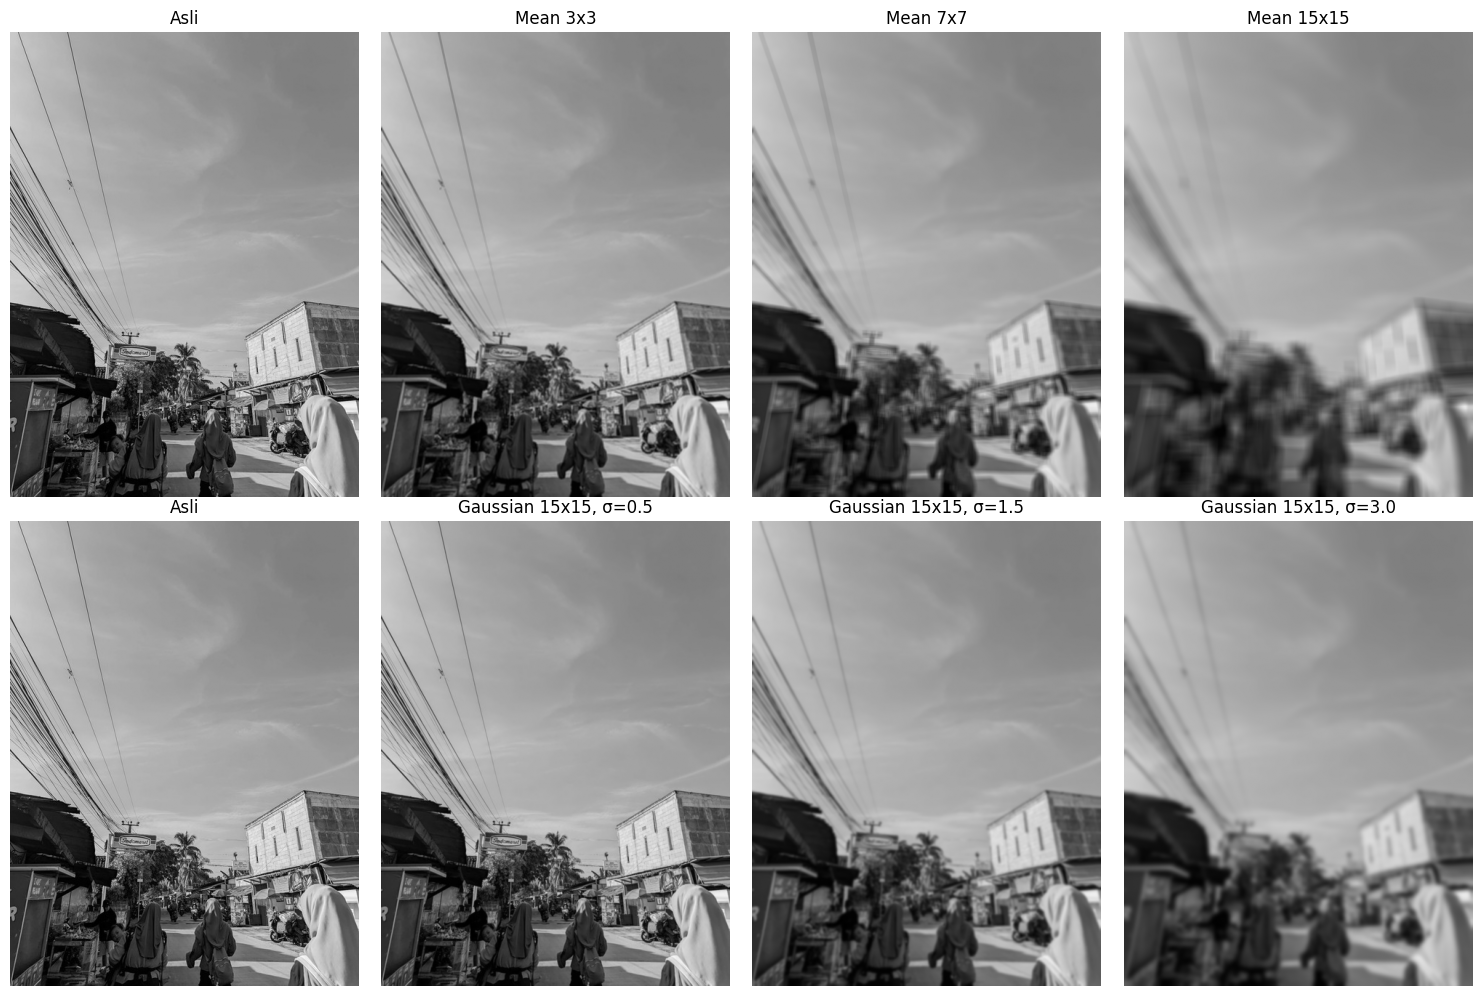

In [10]:
fig, ax = plt.subplots(2, 4, figsize=(15, 10))
ax[0, 0].imshow(citra, cmap="gray"); ax[0, 0].set_title("Asli")
for a, n in zip(ax[0, 1:], [3, 7, 15]):
    a.imshow(clip8(konvolusi2d(citra, np.ones((n, n)) / n**2)), cmap="gray", vmin=0, vmax=255)
    a.set_title(f"Mean {n}x{n}")
ax[1, 0].imshow(citra, cmap="gray"); ax[1, 0].set_title("Asli")
for a, s in zip(ax[1, 1:], [0.5, 1.5, 3.0]):
    a.imshow(clip8(konvolusi2d(citra, kernel_gaussian(15, s))), cmap="gray", vmin=0, vmax=255)
    a.set_title(f"Gaussian 15x15, σ={s}")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 8. Uji pada foto ber-noise
Foto dari kamera ponsel relatif bersih, sehingga efek penurun noise sulit terlihat. Untuk memperlihatkannya, kita **tambahkan noise Gaussian** secara sengaja, lalu bandingkan filter. Nilai yang diukur adalah **simpangan baku (std)** pada area langit yang seharusnya mulus: makin kecil berarti makin bersih.

Std area langit (makin kecil = makin halus):
  Foto bersih :   5.50
  Ber-noise   :  20.81
  + Mean      :   6.97
  + Gaussian  :   8.13
  + Sharpen   :  84.78   (naik = noise ikut dipertajam)


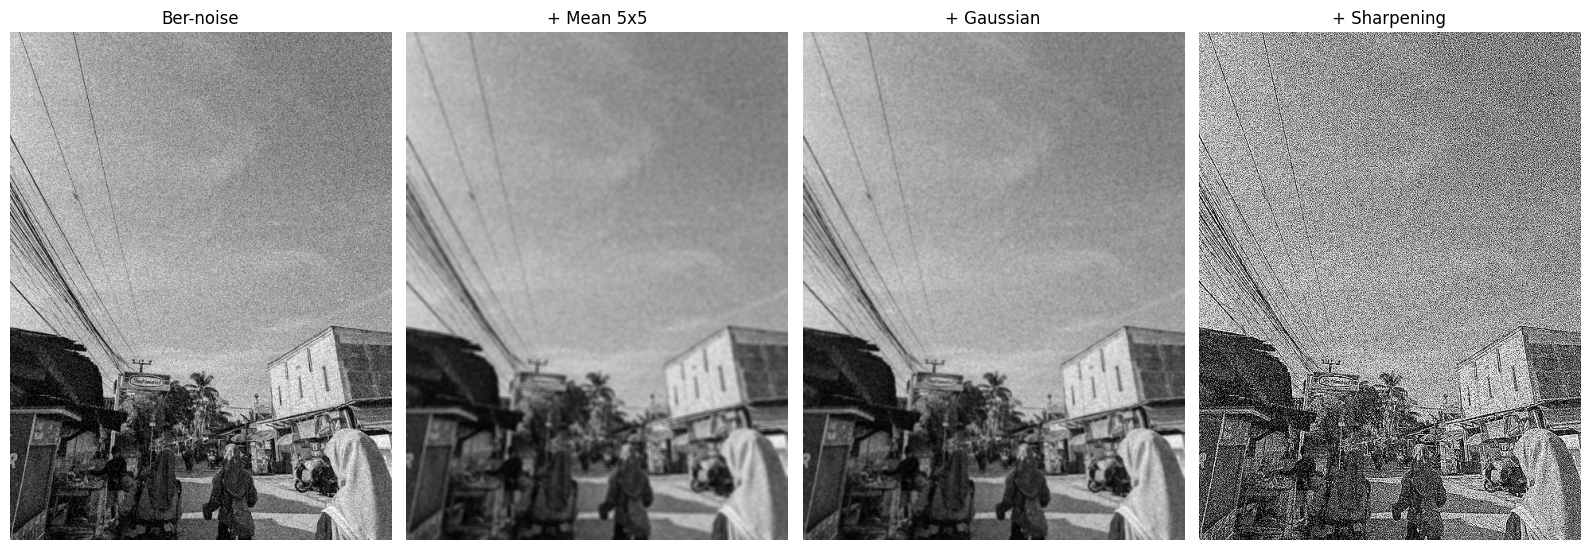

In [11]:
rng = np.random.default_rng(0)
ber_noise = clip8(citra + rng.normal(0, 20, citra.shape))     # noise Gaussian, std = 20

n_mean  = clip8(konvolusi2d(ber_noise, kernel_mean))
n_gauss = clip8(konvolusi2d(ber_noise, kernel_gauss))
n_sharp = clip8(konvolusi2d(ber_noise, kernel_sharpen))

# area langit yang relatif rata (baris 60-160, kolom 300-440)
# catatan: langit punya gradasi alami, jadi std bersihnya tidak 0
langit = (slice(60, 160), slice(300, 440))
print("Std area langit (makin kecil = makin halus):")
print(f"  Foto bersih : {citra[langit].std():6.2f}")
print(f"  Ber-noise   : {ber_noise[langit].std():6.2f}")
print(f"  + Mean      : {n_mean[langit].std():6.2f}")
print(f"  + Gaussian  : {n_gauss[langit].std():6.2f}")
print(f"  + Sharpen   : {n_sharp[langit].std():6.2f}   (naik = noise ikut dipertajam)")

fig, ax = plt.subplots(1, 4, figsize=(16, 6.5))
for a, (j, im) in zip(ax, [("Ber-noise", ber_noise), ("+ Mean 5x5", n_mean),
                           ("+ Gaussian", n_gauss), ("+ Sharpening", n_sharp)]):
    a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(j); a.axis("off")
plt.tight_layout(); plt.show()

## 9. Kesimpulan
- **Mean dan Gaussian** menghaluskan citra dan menurunkan noise. Gaussian lebih alami karena bobot terbesar ada di tengah, sehingga tepi lebih terjaga.
- **Sharpening** mempertegas detail (kabel, papan nama, tekstur dinding), tetapi **noise ikut menguat**.
- **Sobel** menampilkan kontur objek (kabel listrik, bangunan, orang) dan relatif bersih. **Laplacian** menampilkan tepi lebih tipis tetapi lebih sensitif terhadap tekstur halus seperti dedaunan.
- Konvolusi adalah **operasi area**: nilai piksel baru bergantung pada piksel dan tetangganya.

**Referensi:** Gonzalez & Woods, *Digital Image Processing*, bab *Spatial Filtering*.